# 04 — Patient-Level Train / Val / Test Split

This is **Phase 5** of the diabetic foot thermography project. Inputs are `data/processed/subject_metadata.csv` (167 rows, one per subject) and `data/processed/preprocessing_manifest.csv` (334 rows, one per subject + foot side), produced by `01_data_loading_integrity.ipynb` and `03_preprocessing.ipynb` respectively. This notebook does **not** re-parse the raw Excel file and does **not** re-walk the `ThermoDataBase` directory tree — those files are the single source of truth from here on.

**Why this split is not a simple random split:**

1. **Patient-level, not file-level.** `preprocessing_manifest.csv` has two rows per subject (left foot, right foot). Both feet of the same subject must end up in the same split, or a subject's own physiology could leak from train into test via the other foot. All splitting logic below operates on unique `Subject` values from `subject_metadata.csv`; the split label is then joined onto `preprocessing_manifest.csv`, never computed independently per row.
2. **Class imbalance.** 45 Control vs. 122 DM subjects (2.7:1), confirmed in Phase 1/2. Every split must preserve this ratio as closely as possible.
3. **Known confounders.** Phase 3 EDA found Gender, Age, Height, and BMI all differ significantly between Control and DM. The dataset-level confound can't be removed by splitting, but the split itself must not make it worse through bad luck — so this notebook stratifies jointly on Group + Gender wherever every stratum is large enough, with a safe fallback to Group-only stratification if not, and reports per-split demographics explicitly either way.


## Section 1 — Setup

Load the two processed files this notebook depends on and confirm they loaded correctly (shape + dtypes) before doing anything else. `RANDOM_SEED = 42` matches the convention already established in `02_eda.ipynb` and `03_preprocessing.ipynb`, so sampling and split behavior stay reproducible and consistent across the whole project. Output paths are defined here as the only things that should need to change on another machine.


In [2]:
print("=== SECTION 1: Setup ===")

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Running log of any issues found, printed in the final summary cell
issues_log = []

# --- Inputs (already-processed; do not re-derive from raw Excel or the raw directory tree) ---
PROCESSED_DIR = Path("data/processed")
METADATA_PATH = PROCESSED_DIR / "subject_metadata.csv"
PREPROCESSING_MANIFEST_PATH = PROCESSED_DIR / "preprocessing_manifest.csv"

# --- Outputs ---
OUTPUT_PATH = PROCESSED_DIR / "patient_split.csv"
SPLIT_MANIFEST_PATH = PROCESSED_DIR / "split_manifest.csv"

metadata_df = pd.read_csv(METADATA_PATH)
preprocessing_manifest_df = pd.read_csv(PREPROCESSING_MANIFEST_PATH)

print(f"metadata_df loaded: shape = {metadata_df.shape}")
print(metadata_df.dtypes)
print()
print(f"preprocessing_manifest_df loaded: shape = {preprocessing_manifest_df.shape}")
print(preprocessing_manifest_df.dtypes)


=== SECTION 1: Setup ===
metadata_df loaded: shape = (167, 19)
Subject              str
Gender               str
Age_years        float64
Weight_kg        float64
Height_m         float64
BMI              float64
RIGHT_General    float64
RIGHT_LCA        float64
RIGHT_LPA        float64
RIGHT_MCA        float64
RIGHT_MPA        float64
RIGHT_TCI        float64
LEFT_General     float64
LEFT_LCA         float64
LEFT_LPA         float64
LEFT_MCA         float64
LEFT_MPA         float64
LEFT_TCI         float64
Group                str
dtype: object

preprocessing_manifest_df loaded: shape = (334, 14)
subject_id               str
group                    str
gender                   str
foot_side                str
original_height        int64
original_width         int64
pad_row_offset         int64
pad_col_offset         int64
canonical_height       int64
canonical_width        int64
raw_array_path           str
mask_path                str
relative_array_path      str
colormap_png_path 

## Section 2 — Reconfirm Class Balance

Recompute subject counts per `Group`, and `Gender` counts within each `Group`, directly from `metadata_df` — nothing here is assumed from earlier phases. If the 45 Control / 122 DM split reported since Phase 1 doesn't hold, the notebook stops with a loud warning rather than silently splitting on the wrong basis.


In [3]:
print("=== SECTION 2: Reconfirm Class Balance ===")

group_counts = metadata_df["Group"].value_counts()
print("Subject counts per Group:")
print(group_counts)
print()

gender_crosstab = pd.crosstab(metadata_df["Group"], metadata_df["Gender"])
print("Gender counts within each Group (cross-tab):")
print(gender_crosstab)
print()

n_control = int(group_counts.get("Control", 0))
n_dm = int(group_counts.get("DM", 0))
n_total = len(metadata_df)

if n_control == 45 and n_dm == 122 and n_total == 167:
    print(f"OK — confirmed 45 Control / 122 DM / 167 total, matches Phase 1/2 exactly.")
else:
    warning = (f"!!! WARNING !!! Class balance does NOT match expected 45 Control / 122 DM "
               f"(got {n_control} Control / {n_dm} DM / {n_total} total). Stopping before any split "
               f"is computed — investigate subject_metadata.csv before proceeding.")
    print(warning)
    issues_log.append(warning)
    raise ValueError(warning)


=== SECTION 2: Reconfirm Class Balance ===
Subject counts per Group:
Group
DM         122
Control     45
Name: count, dtype: int64

Gender counts within each Group (cross-tab):
Gender    F   M
Group          
Control  16  29
DM       89  33

OK — confirmed 45 Control / 122 DM / 167 total, matches Phase 1/2 exactly.


## Section 3 — Split Ratios

70% train / 15% val / 15% test, applied at the **subject** level (not the file/row level). Printing the target count per split per `Group` up front gives a concrete expectation to check the actual split against in Section 6.


In [4]:
print("=== SECTION 3: Split Ratios ===")

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15
TEST_FRAC = 0.15
assert abs((TRAIN_FRAC + VAL_FRAC + TEST_FRAC) - 1.0) < 1e-9

print(f"Target split ratios: {TRAIN_FRAC:.0%} train / {VAL_FRAC:.0%} val / {TEST_FRAC:.0%} test (subject-level)")
print()

for grp, n in group_counts.items():
    n_train = n * TRAIN_FRAC
    n_val = n * VAL_FRAC
    n_test = n * TEST_FRAC
    print(f"{grp}: ~{n_train:.1f} train / ~{n_val:.1f} val / ~{n_test:.1f} test  (of {n} total)")


=== SECTION 3: Split Ratios ===
Target split ratios: 70% train / 15% val / 15% test (subject-level)

DM: ~85.4 train / ~18.3 val / ~18.3 test  (of 122 total)
Control: ~31.5 train / ~6.8 val / ~6.8 test  (of 45 total)


## Section 4 — Stratified Split (with Safe Fallback)

Build a combined stratify key `Group + "_" + Gender` for every subject (e.g. `"Control_M"`, `"DM_F"`). If every resulting stratum is large enough to survive two sequential `train_test_split` calls (train vs. temp, then val vs. test) without scikit-learn raising a "least populated class" error, use the combined key. If any stratum is too small, that failure is caught explicitly, the offending stratum is printed, and the notebook falls back to stratifying on `Group` alone — it will not crash, and it will not downgrade silently. `random_state=RANDOM_SEED` on every split call keeps this fully reproducible.


In [5]:
print("=== SECTION 4: Stratified Split (with Safe Fallback) ===")

metadata_df["stratify_key"] = metadata_df["Group"] + "_" + metadata_df["Gender"]
combined_strata_counts = metadata_df["stratify_key"].value_counts()
print("Combined Group+Gender stratum sizes:")
print(combined_strata_counts)
print()

def two_step_split(df, stratify_col):
    # train vs temp (70/30), then temp -> val vs test (50/50), both stratified.
    train_df, temp_df = train_test_split(
        df, test_size=(VAL_FRAC + TEST_FRAC),
        stratify=df[stratify_col], random_state=RANDOM_SEED,
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=(TEST_FRAC / (VAL_FRAC + TEST_FRAC)),
        stratify=temp_df[stratify_col], random_state=RANDOM_SEED,
    )
    return train_df, val_df, test_df

used_combined_key = False
fallback_reason = None

try:
    train_df, val_df, test_df = two_step_split(metadata_df, "stratify_key")
    used_combined_key = True
    print("Combined Group+Gender stratification SUCCEEDED — every stratum was large enough "
          "to survive both split steps. Using the combined key.")
except ValueError as e:
    fallback_reason = str(e)
    print("Combined Group+Gender stratification FAILED:")
    print(f"  {fallback_reason}")
    print("Falling back to stratifying on Group alone.")
    issues_log.append(f"SECTION 4: fell back to Group-only stratification because: {fallback_reason}")
    train_df, val_df, test_df = two_step_split(metadata_df, "Group")

print()
print(f"Stratification key actually used: {'Group + Gender (combined)' if used_combined_key else 'Group only (fallback)'}")
print(f"Resulting sizes: train={len(train_df)}, val={len(val_df)}, test={len(test_df)}")


=== SECTION 4: Stratified Split (with Safe Fallback) ===
Combined Group+Gender stratum sizes:
stratify_key
DM_F         89
DM_M         33
Control_M    29
Control_F    16
Name: count, dtype: int64

Combined Group+Gender stratification SUCCEEDED — every stratum was large enough to survive both split steps. Using the combined key.

Stratification key actually used: Group + Gender (combined)
Resulting sizes: train=116, val=25, test=26


## Section 5 — Leakage Check

The single most important check in this notebook. Verifies programmatically that every subject appears in **exactly one** of train/val/test, that the three splits are pairwise disjoint, and that their union is exactly the full set of 167 subjects with none missing and none duplicated.


In [6]:
print("=== SECTION 5: Leakage Check ===")

train_ids = set(train_df["Subject"])
val_ids = set(val_df["Subject"])
test_ids = set(test_df["Subject"])
all_subject_ids = set(metadata_df["Subject"])

checks = {}

# (a) every subject in exactly one split
subject_split_count = {}
for sid in all_subject_ids:
    c = (sid in train_ids) + (sid in val_ids) + (sid in test_ids)
    subject_split_count[sid] = c
not_exactly_one = {sid: c for sid, c in subject_split_count.items() if c != 1}
checks["(a) every subject in exactly one split"] = (len(not_exactly_one) == 0, not_exactly_one)

# (b) pairwise disjoint
overlap_train_val = train_ids & val_ids
overlap_train_test = train_ids & test_ids
overlap_val_test = val_ids & test_ids
disjoint_ok = not (overlap_train_val or overlap_train_test or overlap_val_test)
checks["(b) train/val/test pairwise disjoint"] = (
    disjoint_ok,
    {"train&val": overlap_train_val, "train&test": overlap_train_test, "val&test": overlap_val_test},
)

# (c) union == all 167, no missing, no duplicates
union_ids = train_ids | val_ids | test_ids
missing = all_subject_ids - union_ids
extra = union_ids - all_subject_ids
total_rows_across_splits = len(train_df) + len(val_df) + len(test_df)
no_dupes = total_rows_across_splits == len(union_ids)
union_ok = (union_ids == all_subject_ids) and no_dupes
checks["(c) union == all 167 subjects, no missing/duplicated"] = (
    union_ok,
    {"missing": missing, "unexpected_extra": extra, "duplicate_rows": total_rows_across_splits - len(union_ids)},
)

all_passed = True
for label, (passed, detail) in checks.items():
    status = "PASS" if passed else "FAIL"
    print(f"{label}: {status}")
    if not passed:
        all_passed = False
        print(f"  detail: {detail}")
        issues_log.append(f"SECTION 5: {label} FAILED — {detail}")

print()
if all_passed:
    print(">>> LEAKAGE CHECK: ALL PASS. No subject-level leakage between splits. <<<")
else:
    print(">>> LEAKAGE CHECK: FAILED — see details above. Do not proceed to modeling with this split. <<<")


=== SECTION 5: Leakage Check ===
(a) every subject in exactly one split: PASS
(b) train/val/test pairwise disjoint: PASS
(c) union == all 167 subjects, no missing/duplicated: PASS

>>> LEAKAGE CHECK: ALL PASS. No subject-level leakage between splits. <<<


## Section 6 — Per-Split Balance Report

For each split, print subject count, `Group` counts/percentages, `Gender` counts/percentages within each `Group`, and mean/std of `Age_years`, `BMI`, and `Height_m`. This is descriptive, not a statistical test — the goal is just to visually confirm no split ended up wildly different from the others by chance, given the known confounders from Phase 3. A grouped bar chart shows `Group` counts across the three splits using the same color convention as `02_eda.ipynb` (Control = blue `#1f77b4`, DM = orange `#ff7f0e`).


=== SECTION 6: Per-Split Balance Report ===
--- train (n=116) ---
Group counts (and %):
  DM: 85 (73.3%)
  Control: 31 (26.7%)
Gender counts within each Group (and % within that Group):
  Control / M: 20 (64.5%)
  Control / F: 11 (35.5%)
  DM / F: 62 (72.9%)
  DM / M: 23 (27.1%)
Age_years / BMI / Height_m (mean +/- std):
  Age_years: 47.95 +/- 16.05
  BMI: 28.64 +/- 5.24
  Height_m: 1.57 +/- 0.10

--- val (n=25) ---
Group counts (and %):
  DM: 18 (72.0%)
  Control: 7 (28.0%)
Gender counts within each Group (and % within that Group):
  Control / M: 4 (57.1%)
  Control / F: 3 (42.9%)
  DM / F: 13 (72.2%)
  DM / M: 5 (27.8%)
Age_years / BMI / Height_m (mean +/- std):
  Age_years: 46.84 +/- 13.42
  BMI: 28.02 +/- 5.45
  Height_m: 1.60 +/- 0.10

--- test (n=26) ---
Group counts (and %):
  DM: 19 (73.1%)
  Control: 7 (26.9%)
Gender counts within each Group (and % within that Group):
  Control / M: 5 (71.4%)
  Control / F: 2 (28.6%)
  DM / F: 14 (73.7%)
  DM / M: 5 (26.3%)
Age_years / BMI / H

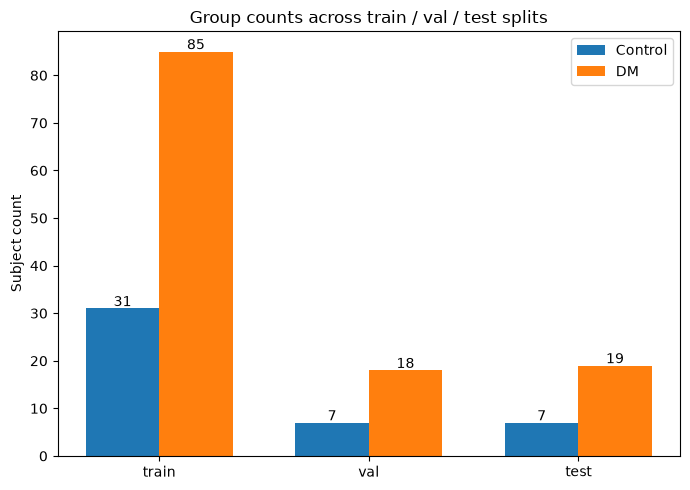

In [7]:
print("=== SECTION 6: Per-Split Balance Report ===")

splits = {"train": train_df, "val": val_df, "test": test_df}

for split_name, split_df in splits.items():
    print(f"--- {split_name} (n={len(split_df)}) ---")
    grp_counts = split_df["Group"].value_counts()
    grp_pct = (split_df["Group"].value_counts(normalize=True) * 100).round(1)
    print("Group counts (and %):")
    for g in grp_counts.index:
        print(f"  {g}: {grp_counts[g]} ({grp_pct[g]}%)")

    print("Gender counts within each Group (and % within that Group):")
    for g in sorted(split_df["Group"].unique()):
        sub = split_df.loc[split_df["Group"] == g, "Gender"]
        counts = sub.value_counts()
        pct = (sub.value_counts(normalize=True) * 100).round(1)
        for gender in counts.index:
            print(f"  {g} / {gender}: {counts[gender]} ({pct[gender]}%)")

    print("Age_years / BMI / Height_m (mean +/- std):")
    for col in ["Age_years", "BMI", "Height_m"]:
        print(f"  {col}: {split_df[col].mean():.2f} +/- {split_df[col].std():.2f}")
    print()

# --- Grouped bar chart: Group counts across the three splits ---
COLOR_CONTROL = "#1f77b4"
COLOR_DM = "#ff7f0e"

split_order = ["train", "val", "test"]
control_counts = [splits[s]["Group"].value_counts().get("Control", 0) for s in split_order]
dm_counts = [splits[s]["Group"].value_counts().get("DM", 0) for s in split_order]

x = np.arange(len(split_order))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(x - width/2, control_counts, width, label="Control", color=COLOR_CONTROL)
ax.bar(x + width/2, dm_counts, width, label="DM", color=COLOR_DM)
ax.set_xticks(x)
ax.set_xticklabels(split_order)
ax.set_ylabel("Subject count")
ax.set_title("Group counts across train / val / test splits")
ax.legend()
for i, (c, d) in enumerate(zip(control_counts, dm_counts)):
    ax.text(i - width/2, c + 0.5, str(c), ha="center")
    ax.text(i + width/2, d + 0.5, str(d), ha="center")
plt.tight_layout()
plt.show()


## Section 7 — Class Weights for Later Use

Inverse-frequency class weights for Control vs. DM, computed from the **training split only** (not the full dataset — using val/test counts here would leak split-composition information into a quantity meant to correct for train-time imbalance). These are only computed and printed here for record-keeping; they are not applied in this notebook.


In [8]:
print("=== SECTION 7: Class Weights (computed from TRAIN split only) ===")

train_group_counts = train_df["Group"].value_counts()
n_train_total = len(train_df)
n_classes = train_group_counts.shape[0]

class_weights = {
    grp: n_train_total / (n_classes * count)
    for grp, count in train_group_counts.items()
}

print(f"Training split composition: {dict(train_group_counts)}")
print()
print("Inverse-frequency class weights (for use in Phase 10's training loop, e.g. weighted loss):")
for grp, w in class_weights.items():
    print(f"  {grp}: {w:.4f}")


=== SECTION 7: Class Weights (computed from TRAIN split only) ===
Training split composition: {'DM': np.int64(85), 'Control': np.int64(31)}

Inverse-frequency class weights (for use in Phase 10's training loop, e.g. weighted loss):
  DM: 0.6824
  Control: 1.8710


## Section 8 — Save `patient_split.csv`

One row per subject: `Subject`, `Group`, `Gender`, `Age_years`, `BMI`, `split` (`train`/`val`/`test`). This is the subject-level record of the split decision itself.


In [9]:
print("=== SECTION 8: Save patient_split.csv ===")

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()
train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

patient_split_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
patient_split_df = patient_split_df[["Subject", "Group", "Gender", "Age_years", "BMI", "split"]]

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
patient_split_df.to_csv(OUTPUT_PATH, index=False)

print(f"Saved: {OUTPUT_PATH}")
print(f"Final shape: {patient_split_df.shape} (expected (167, 6))")
if patient_split_df.shape != (167, 6):
    issues_log.append(f"SECTION 8: patient_split_df shape {patient_split_df.shape} != expected (167, 6)")
print()
print(patient_split_df.head())


=== SECTION 8: Save patient_split.csv ===
Saved: data\processed\patient_split.csv
Final shape: (167, 6) (expected (167, 6))

  Subject    Group Gender  Age_years        BMI  split
0   CG036  Control      M       22.0  20.661157  train
1   DM069       DM      F       53.0  42.980571  train
2   DM045       DM      F       62.0        NaN  train
3   CG040  Control      M       29.0  25.990903  train
4   CG042  Control      F       24.0  23.624447  train


## Section 9 — Build & Save `split_manifest.csv`

Left-join the `split` column from `patient_split_df` onto `preprocessing_manifest_df` (matching `subject_id` to `Subject`), producing one row per subject + foot side (334 rows) that carries every preprocessing artifact path **and** its split assignment in a single file. This becomes the file later `Dataset`/`DataLoader` classes should read. Verified that no row failed to match (no null `split` after the join).


In [10]:
print("=== SECTION 9: Build & Save split_manifest.csv ===")

split_manifest_df = preprocessing_manifest_df.merge(
    patient_split_df[["Subject", "split"]],
    left_on="subject_id", right_on="Subject",
    how="left",
)
split_manifest_df = split_manifest_df.drop(columns=["Subject"])

n_null_split = split_manifest_df["split"].isna().sum()
print(f"Rows with null split after join: {n_null_split}")
if n_null_split > 0:
    issue = f"SECTION 9: {n_null_split} rows in split_manifest_df have a null split after the join"
    print(f"!!! {issue}")
    issues_log.append(issue)
    print(split_manifest_df.loc[split_manifest_df["split"].isna()])
else:
    print("OK — every row matched a split assignment.")

split_manifest_df.to_csv(SPLIT_MANIFEST_PATH, index=False)
print()
print(f"Saved: {SPLIT_MANIFEST_PATH}")
print(f"Final shape: {split_manifest_df.shape} (expected (334, 15))")
if split_manifest_df.shape != (334, 15):
    issues_log.append(f"SECTION 9: split_manifest_df shape {split_manifest_df.shape} != expected (334, 15)")
print()
print(split_manifest_df.head())


=== SECTION 9: Build & Save split_manifest.csv ===
Rows with null split after join: 0
OK — every row matched a split assignment.

Saved: data\processed\split_manifest.csv
Final shape: (334, 15) (expected (334, 15))

  subject_id    group gender foot_side  original_height  original_width  \
0      CG001  Control      M         L              168              65   
1      CG001  Control      M         R              175              63   
2      CG002  Control      M         L              179              69   
3      CG002  Control      M         R              179              69   
4      CG003  Control      M         L              194              72   

   pad_row_offset  pad_col_offset  canonical_height  canonical_width  \
0              20              15               208               96   
1              16              16               208               96   
2              14              13               208               96   
3              14              13            

## Section 10 — Final Summary


In [11]:
print("=== SECTION 10: Final Summary ===")

print(f"Total subjects: {len(metadata_df)}")
print()

print("Split sizes achieved (target 70/15/15):")
for split_name, split_df in splits.items():
    pct = 100 * len(split_df) / len(metadata_df)
    print(f"  {split_name}: {len(split_df)} subjects ({pct:.1f}%)")
print()

print(f"Leakage check: {'PASSED' if all_passed else 'FAILED'}")
print()

print(f"Stratification: {'combined Group+Gender key' if used_combined_key else 'Group-only fallback'}")
if not used_combined_key:
    print(f"  Fallback reason: {fallback_reason}")
print()

print("Class weights (from TRAIN split, for Phase 10's weighted loss):")
for grp, w in class_weights.items():
    print(f"  {grp}: {w:.4f}")
print()

print(f"patient_split.csv saved to {OUTPUT_PATH} with shape {patient_split_df.shape} (expected (167, 6))")
print(f"split_manifest.csv saved to {SPLIT_MANIFEST_PATH} with shape {split_manifest_df.shape} (expected (334, 15))")
print()

print("--- Integrity issues found across Sections 2-10 ---")
if issues_log:
    for issue in issues_log:
        print(" -", issue)
else:
    print("0 issues found.")


=== SECTION 10: Final Summary ===
Total subjects: 167

Split sizes achieved (target 70/15/15):
  train: 116 subjects (69.5%)
  val: 25 subjects (15.0%)
  test: 26 subjects (15.6%)

Leakage check: PASSED

Stratification: combined Group+Gender key

Class weights (from TRAIN split, for Phase 10's weighted loss):
  DM: 0.6824
  Control: 1.8710

patient_split.csv saved to data\processed\patient_split.csv with shape (167, 6) (expected (167, 6))
split_manifest.csv saved to data\processed\split_manifest.csv with shape (334, 15) (expected (334, 15))

--- Integrity issues found across Sections 2-10 ---
0 issues found.
